# Customers Like You: PCA or SVD

**Dataset:** UCI Online Retail II  
**Purpose:** Explore customer-product patterns, compare PCA and Truncated SVD, evaluate recommendations, and investigate customer segments.

This notebook reads the outputs generated by the project scripts. It is designed to document and inspect the recorded results without automatically rerunning all experiments.

## Research questions

1. How does dimensionality reduction represent sparse customer-product purchase patterns?
2. How do PCA and Truncated SVD compare on explained variance, reconstruction error, fitting time, and Hit Rate@10?
3. What exploratory customer groups emerge from the reduced representations?

**Reproducibility:** Run this notebook from the project root, `customers-like-you`.


## 1. Imports and paths

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Find the project root automatically
HERE = Path.cwd()

if (HERE / "reports" / "matrix_report.csv").exists():
    ROOT = HERE
elif (HERE.parent / "reports" / "matrix_report.csv").exists():
    ROOT = HERE.parent
else:
    raise FileNotFoundError(
        "Could not locate reports/matrix_report.csv. "
        f"Current directory: {HERE}"
    )

REPORTS = ROOT / "reports"

print("Project root:", ROOT)
print("Reports folder:", REPORTS)
print("Matrix report found:",
      (REPORTS / "matrix_report.csv").exists())

Project root: D:\Adi_Boston\MiniProject\customers-like-you
Reports folder: D:\Adi_Boston\MiniProject\customers-like-you\reports
Matrix report found: True


## 2. Data profile, cleaning, and chronological split

In [4]:
split = pd.read_csv(REPORTS / "split_summary.csv")
cleaning_log = pd.read_csv(REPORTS / "cleaning_log.csv")
data_profile_path = REPORTS / "data_profile.csv"

print("Chronological split summary")
display(split)

print("Cleaning log")
display(cleaning_log)

if data_profile_path.exists():
    print("Data profile")
    display(pd.read_csv(data_profile_path))


Chronological split summary


,raw_rows,clean_rows,training_rows,test_rows,unseen_test_rows,latest_cleaned_date,test_cutoff,training_customers,test_customers
0,1067371,802965,684357,118608,72924,2011-12-09 12:50:00,2011-10-09 12:50:00,5484,2420


Cleaning log


,rule,rows_before,rows_after,rows_removed,reason
0,Remove cancellation invoices,1067371,1047877,19494,Invoice numbers starting with C
1,Remove invalid quantities,1047877,1044420,3457,Quantity must be greater than zero
2,Remove invalid prices,1044420,1041670,2750,Unit price must be greater than zero
3,Remove known non-product codes,1041670,1038863,2807,"Exclude POST, M, D and BANK CHARGES"
4,Remove missing customer IDs,1038863,802965,235898,Customer-level recommendations require a custo...
5,"Remove invalid invoice, product code or date",802965,802965,0,Essential transaction fields must be present


Data profile


,column,dtype,missing_count,missing_percent
0,Invoice,object,0,0.00
1,StockCode,object,0,0.00
2,Description,object,4382,0.41
3,Quantity,int64,0,0.00
4,InvoiceDate,datetime64[us],0,0.00
5,Price,float64,0,0.00
6,Customer ID,float64,243007,22.77
7,Country,str,0,0.00


### Interpretation

The recorded run contains 1,067,371 raw rows and 802,965 cleaned transactions. The chronological cutoff is recorded in `split_summary.csv`. The training data must precede the held-out period; matrix construction and model fitting should use training data only.


## 3. Customer-product matrix

In [5]:
matrix_report = pd.read_csv(REPORTS / "matrix_report.csv")
display(matrix_report.T.rename(columns={0: "Recorded value"}))

m = matrix_report.iloc[0]
print(f"Matrix dimensions: {int(m['matrix_rows']):,} customers x "
      f"{int(m['matrix_columns']):,} products")
print(f"Nonzero entries: {int(m['nonzero_entries']):,}")
print(f"Sparsity: {m['sparsity_percent']:.2f}%")
print(f"Dense memory: {m['dense_memory_mb']:.2f} MB")
print(f"Sparse memory: {m['sparse_memory_mb']:.3f} MB")


,Recorded value
customers,5483
products,3690
matrix_rows,5483
matrix_columns,3690
nonzero_entries,414008
total_cells,20232270
sparsity_percent,97.9537
dense_memory_mb,154.36
sparse_memory_mb,4.759
memory_reduction_percent,96.917


Matrix dimensions: 5,483 customers x 3,690 products
Nonzero entries: 414,008
Sparsity: 97.95%
Dense memory: 154.36 MB
Sparse memory: 4.759 MB


### Interpretation

The customer-product matrix is highly sparse. In the recorded run, sparse storage required substantially less memory than a dense representation. The matrix was built from training transactions, with aggregated quantities transformed using `log1p`.


## 4. PCA and Truncated SVD comparison

,components,pca_fit_seconds,pca_explained_variance,pca_reconstruction_error,pca_factor_storage_mb,dense_input_mb,svd_fit_seconds,svd_explained_variance,svd_reconstruction_error,svd_factor_storage_mb,pca_hit_rate_at_10,baseline_hit_rate_at_10,svd_hit_rate_at_10,pca_minus_svd_hit_rate,pca_improvement_over_baseline,svd_improvement_over_baseline
0,10,1.1295,0.1986,0.8757,0.7280,154.36,0.139,0.1983,0.8761,0.700,0.3278,0.1741,0.3089,0.0188,0.1537,0.1349
1,20,0.6650,0.2527,0.8456,1.4278,154.36,0.152,0.2525,0.8458,1.400,0.3586,0.1741,0.3508,0.0078,0.1845,0.1767
2,50,0.9119,0.3489,0.7893,3.5274,154.36,0.406,0.3489,0.7894,3.499,0.3785,0.1741,0.3717,0.0068,0.2044,0.1976
3,100,1.1810,0.4472,0.7273,7.0266,154.36,0.605,0.4473,0.7273,6.998,0.3894,0.1741,0.3826,0.0068,0.2154,0.2086
4,200,1.9690,0.5735,0.6388,14.0250,154.36,1.299,0.5736,0.6388,13.997,0.4004,0.1741,0.3994,0.0010,0.2263,0.2253


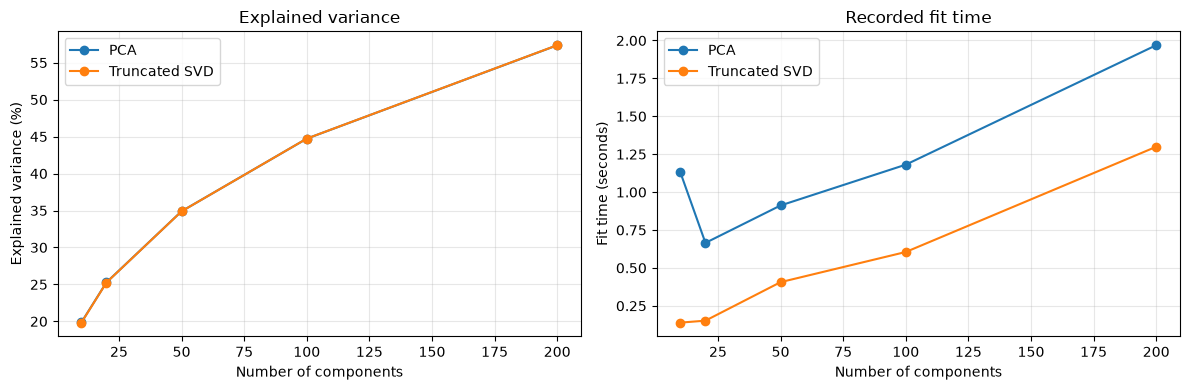

In [6]:
comparison = pd.read_csv(REPORTS / "pca_vs_svd_comparison.csv")
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(comparison["components"],
             comparison["pca_explained_variance"] * 100,
             marker="o", label="PCA")
axes[0].plot(comparison["components"],
             comparison["svd_explained_variance"] * 100,
             marker="o", label="Truncated SVD")
axes[0].set_xlabel("Number of components")
axes[0].set_ylabel("Explained variance (%)")
axes[0].set_title("Explained variance")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(comparison["components"],
             comparison["pca_fit_seconds"],
             marker="o", label="PCA")
axes[1].plot(comparison["components"],
             comparison["svd_fit_seconds"],
             marker="o", label="Truncated SVD")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Fit time (seconds)")
axes[1].set_title("Recorded fit time")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Individual experiment reports

In [7]:
print("PCA experiments")
display(pd.read_csv(REPORTS / "pca_experiments.csv"))

print("Truncated SVD experiments")
display(pd.read_csv(REPORTS / "svd_experiments.csv"))


PCA experiments


,method,n_components,fit_seconds,explained_variance_ratio,relative_reconstruction_error,factor_storage_mb,dense_input_mb,random_state
0,PCA,10,1.129523,0.198640,0.875651,0.727997,154.35997,42
1,PCA,20,0.664961,0.252718,0.845590,1.427841,154.35997,42
2,PCA,50,0.911871,0.348947,0.789270,3.527374,154.35997,42
3,PCA,100,1.180961,0.447216,0.727269,7.026596,154.35997,42
4,PCA,200,1.968966,0.573511,0.638809,14.025040,154.35997,42


Truncated SVD experiments


,components,fit_time_seconds,explained_variance_ratio,relative_reconstruction_error_estimate,customer_factor_mb,product_factor_mb,combined_factor_mb
0,10,0.139,0.198303,0.876086,0.418,0.282,0.700
1,20,0.152,0.252519,0.845842,0.837,0.563,1.400
2,50,0.406,0.348873,0.789411,2.092,1.408,3.499
3,100,0.605,0.447274,0.727293,4.183,2.815,6.998
4,200,1.299,0.573637,0.638758,8.366,5.630,13.997


### Interpretation

At 200 components, PCA and Truncated SVD explain approximately 57.4% of variance and have nearly identical reconstruction error. Truncated SVD was faster in the recorded run and supports sparse input directly. Fit times are specific to this run and environment.


## 5. Recommendation evaluation

PCA recommendation evaluation


,method,components,customers_evaluated,pca_hits_at_10,pca_hit_rate_at_10,baseline_hits_at_10,baseline_hit_rate_at_10,hit_rate_difference,fit_time_seconds,recommendation_scoring_seconds,average_recommendations_per_customer,explained_variance_ratio
0,PCA,10,1913,627,0.327757,333,0.174072,0.153685,0.751622,0.312526,10.0,0.198640
1,PCA,20,1913,686,0.358599,333,0.174072,0.184527,0.680888,0.300833,10.0,0.252718
2,PCA,50,1913,724,0.378463,333,0.174072,0.204391,0.845677,0.346103,10.0,0.348947
3,PCA,100,1913,745,0.389441,333,0.174072,0.215369,1.139250,0.403074,10.0,0.447216
4,PCA,200,1913,766,0.400418,333,0.174072,0.226346,1.955365,0.674477,10.0,0.573511


SVD recommendation evaluation


,method,components,customers_evaluated,svd_hits_at_10,svd_hit_rate_at_10,baseline_hits_at_10,baseline_hit_rate_at_10,hit_rate_difference,fit_time_seconds,recommendation_scoring_seconds,average_recommendations_per_customer,explained_variance_ratio
0,Truncated SVD,10,1913,591,0.308939,333,0.174072,0.134867,0.314954,0.291302,10.0,0.198303
1,Truncated SVD,20,1913,671,0.350758,333,0.174072,0.176686,0.186027,0.288343,10.0,0.252519
2,Truncated SVD,50,1913,711,0.371668,333,0.174072,0.197595,0.356469,0.321156,10.0,0.348873
3,Truncated SVD,100,1913,732,0.382645,333,0.174072,0.208573,0.641545,0.383846,10.0,0.447274
4,Truncated SVD,200,1913,764,0.399373,333,0.174072,0.225301,1.261344,0.704232,10.0,0.573637


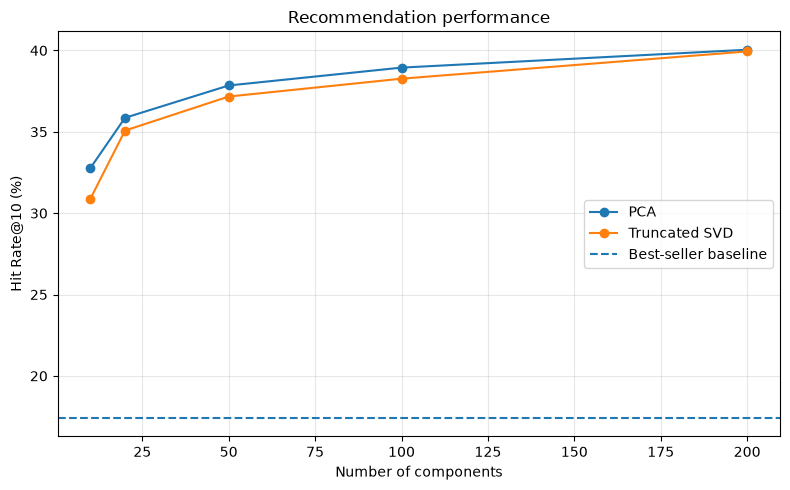

In [8]:
pca_recommendations = pd.read_csv(
    REPORTS / "pca_recommendation_comparison.csv"
)
svd_recommendations = pd.read_csv(
    REPORTS / "svd_recommendation_comparison.csv"
)

print("PCA recommendation evaluation")
display(pca_recommendations)

print("SVD recommendation evaluation")
display(svd_recommendations)

plt.figure(figsize=(8, 5))
plt.plot(comparison["components"],
         comparison["pca_hit_rate_at_10"] * 100,
         marker="o", label="PCA")
plt.plot(comparison["components"],
         comparison["svd_hit_rate_at_10"] * 100,
         marker="o", label="Truncated SVD")
plt.axhline(
    comparison["baseline_hit_rate_at_10"].iloc[0] * 100,
    linestyle="--", label="Best-seller baseline"
)
plt.xlabel("Number of components")
plt.ylabel("Hit Rate@10 (%)")
plt.title("Recommendation performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation and evaluation caveat

At 200 components, the recorded Hit Rate@10 was approximately 40.04% for PCA, 39.94% for Truncated SVD, and 17.41% for the best-seller baseline.

The component-count comparison used the same held-out evaluation data. Consequently, these values are useful for exploratory comparison but may be optimistic if used to select the final model. A separate validation set and an untouched final test set are recommended.


## 6. Customer segmentation

Cluster-count comparison


,n_clusters,silhouette_score,smallest_cluster_size,largest_cluster_size,cluster_size_std,zero_vector_customers,svd_seconds,kmeans_fit_seconds,svd_components,random_state,silhouette_sample_size
0,3,0.015343,1363,2596,670.247964,0,1.160646,5.202285,200,42,1500
1,4,0.014572,775,2578,841.494058,0,1.160646,0.846401,200,42,1500
2,5,0.017308,675,1907,503.299414,0,1.160646,1.049436,200,42,1500
3,6,0.016223,649,1754,427.823055,0,1.160646,1.073893,200,42,1500


Selected five-cluster profile


,cluster,customer_count,avg_orders,median_orders,avg_units,median_units,avg_spend,median_spend,avg_distinct_products,customer_percentage
0,0,997,6.306921,3.0,1993.731194,701.0,2905.771256,1067.520,99.293882,18.183476
1,1,675,10.306667,6.0,3586.074074,1064.0,5870.904938,1914.800,125.385185,12.310779
2,2,1204,6.402824,4.0,1190.425249,486.5,2425.831723,950.345,86.035714,21.958782
3,3,700,6.252857,3.0,2125.631429,759.0,3232.643176,1287.710,94.390000,12.766734
4,4,1907,3.392764,2.0,1041.392764,211.0,1594.674428,395.500,33.831673,34.780230


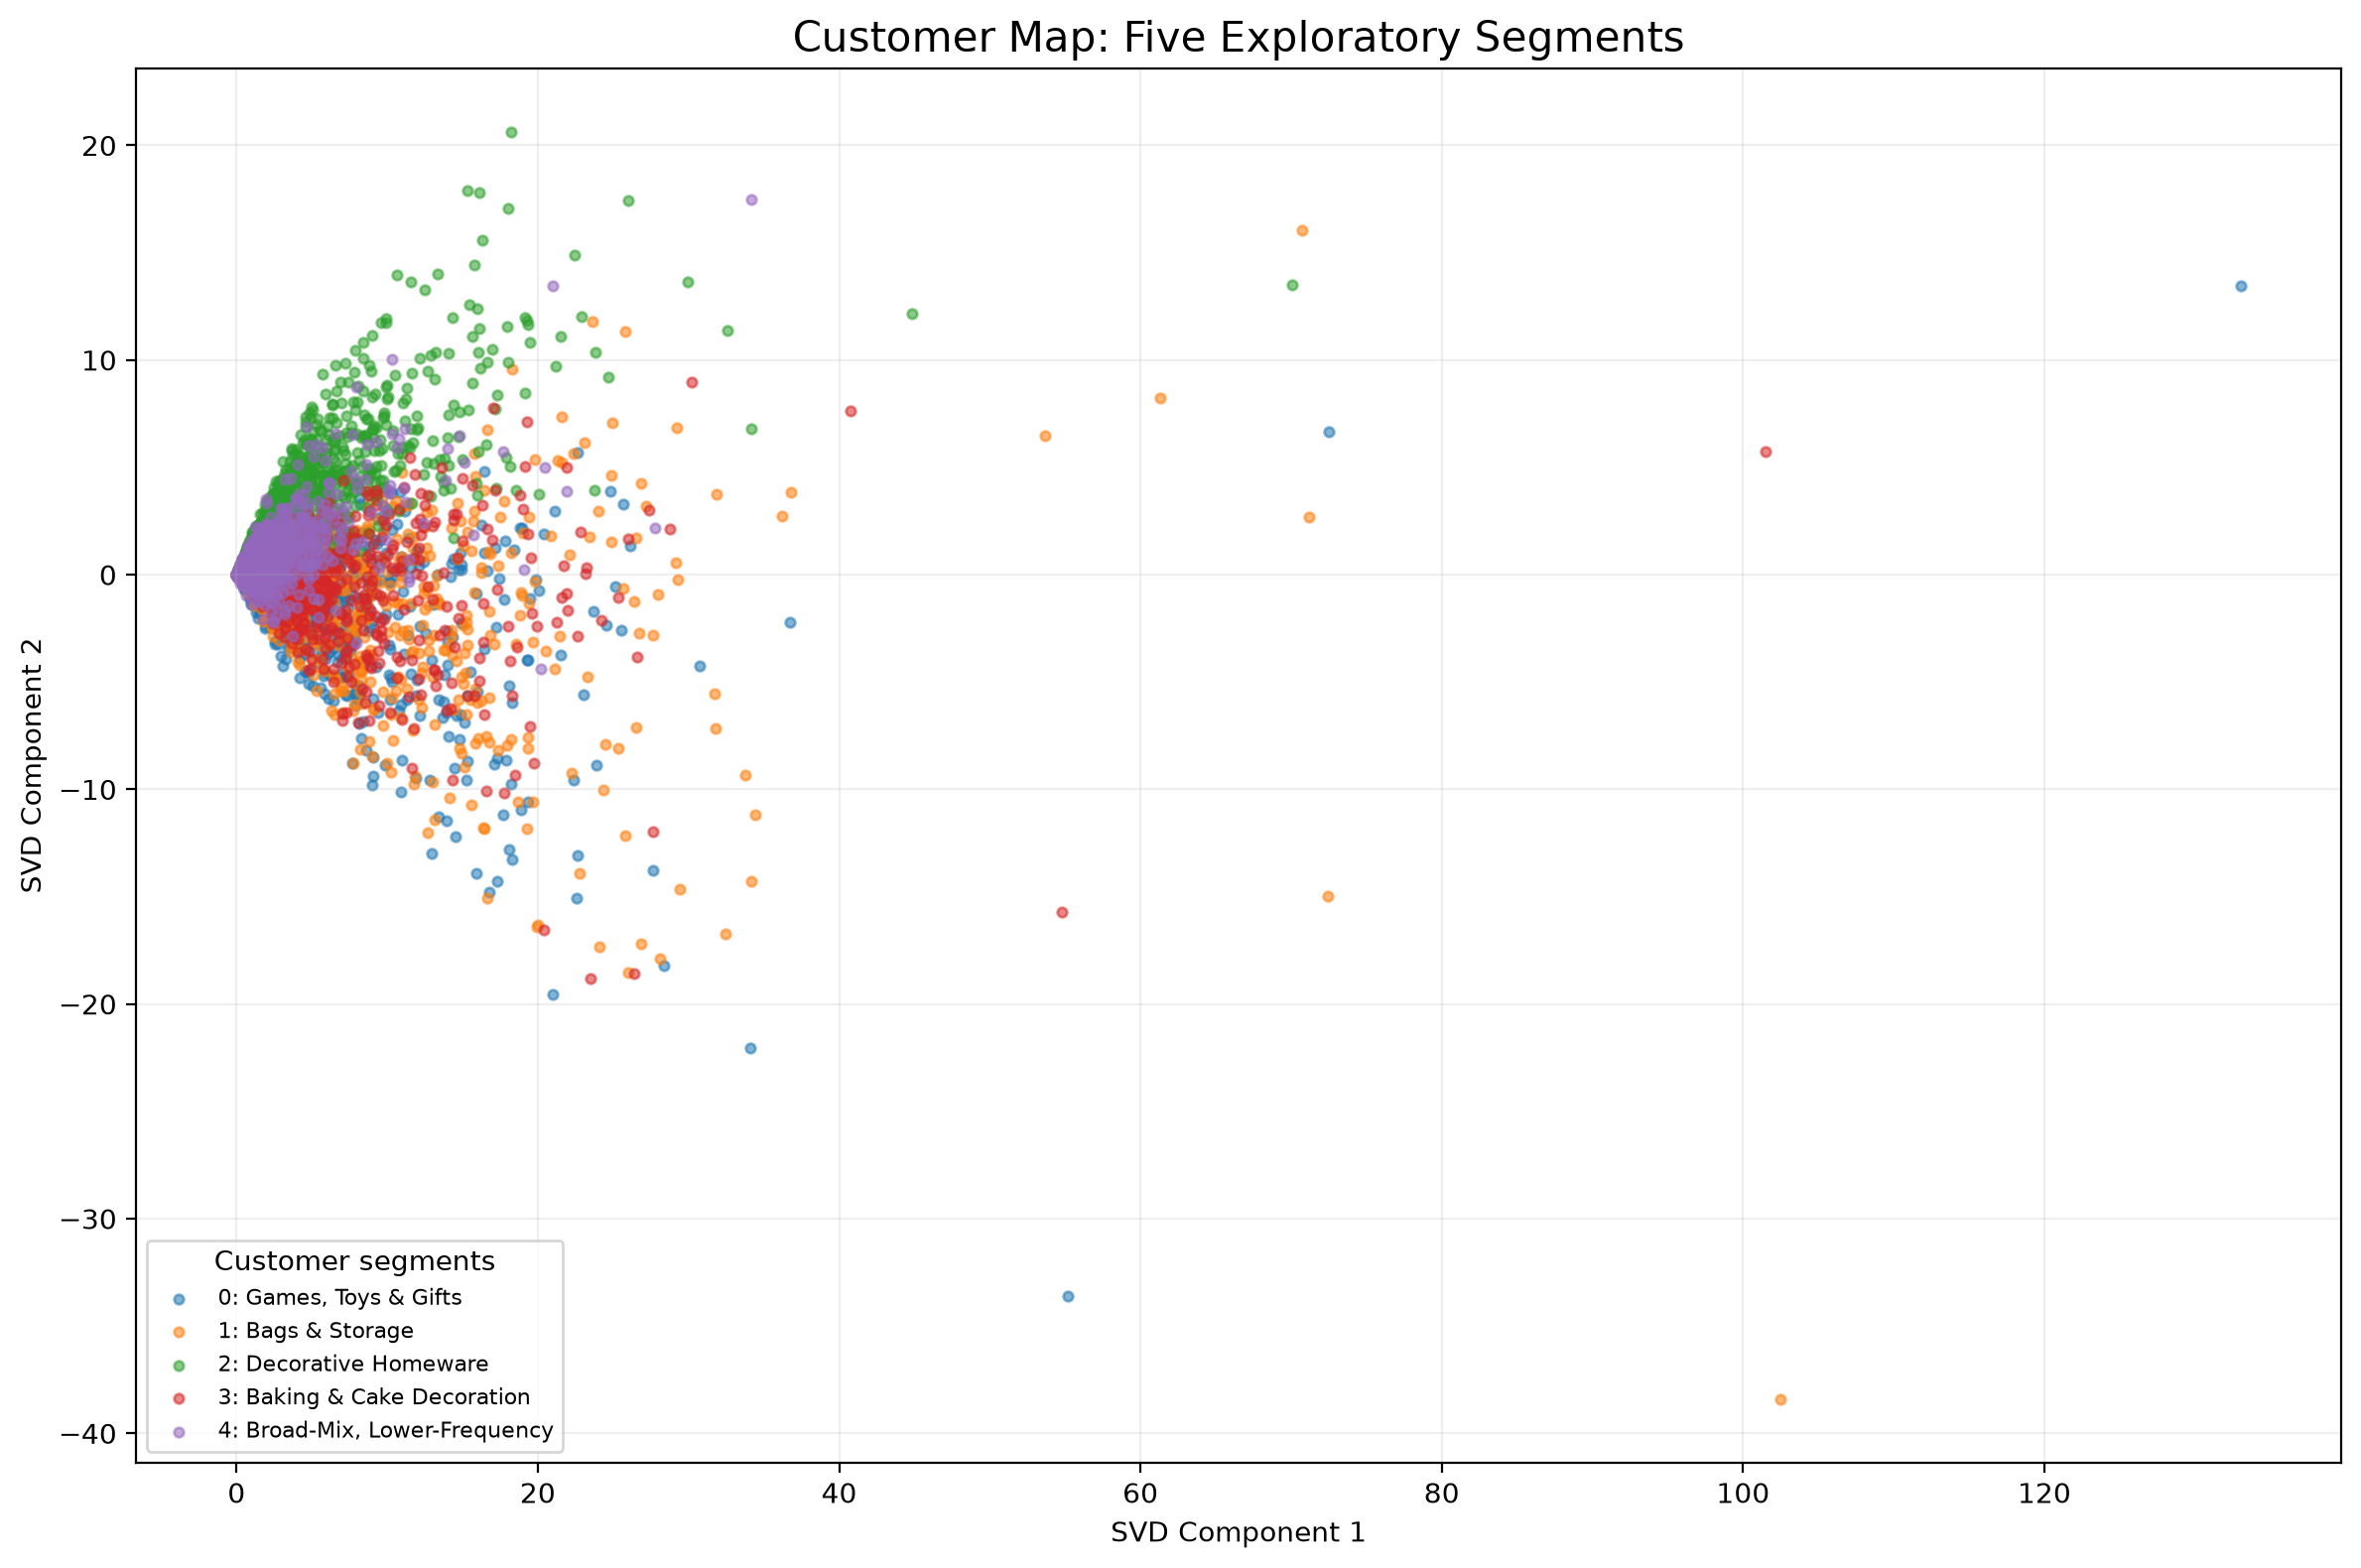

Top products by segment (inspect before external sharing)


,cluster,StockCode,customers_buying_product,segment_customers,customer_penetration_pct,description,rank_within_segment
0,0,21790,368,997,36.910732,VINTAGE SNAP CARDS,1
1,0,21791,340,997,34.102307,VINTAGE HEADS AND TAILS CARD GAME,2
2,0,22138,296,997,29.689067,BAKING SET 9 PIECE RETROSPOT,3
3,0,22139,293,997,29.388164,RETROSPOT TEA SET CERAMIC 11 PC,4
4,0,22561,269,997,26.980943,WOODEN SCHOOL COLOURING SET,5
5,0,22149,262,997,26.278837,FELTCRAFT 6 FLOWER FRIENDS,6
6,0,22551,251,997,25.175527,PLASTERS IN TIN SPACEBOY,7
7,0,22556,250,997,25.075226,PLASTERS IN TIN CIRCUS PARADE,8
8,0,21889,237,997,23.771314,WOODEN BOX OF DOMINOES,9
9,0,21915,237,997,23.771314,RED HARMONICA IN BOX,10


In [9]:
cluster_comparison = pd.read_csv(
    REPORTS / "segmentation_cluster_comparison.csv"
)
segment_summary = pd.read_csv(
    REPORTS / "customer_segment_summary.csv"
)

print("Cluster-count comparison")
display(cluster_comparison)

print("Selected five-cluster profile")
display(segment_summary)

map_path = REPORTS / "final_customer_map_2d.png"
if map_path.exists():
    display(Image(filename=str(map_path), width=850))
else:
    print("Customer map not found:", map_path)

products_path = REPORTS / "segment_top_products_internal.csv"
if products_path.exists():
    print("Top products by segment (inspect before external sharing)")
    display(pd.read_csv(products_path))


### Interpretation

Five clusters were selected as a simpler exploratory solution. Product-based descriptions include Games, Toys & Gifts; Bags & Storage; Decorative Homeware; Baking & Cake Decoration; and Broad-Mix, Lower-Frequency Buyers.

The five-cluster silhouette score is approximately 0.0173, indicating weak separation. These are provisional descriptions of purchasing patterns, not validated customer personas. The two-dimensional map also captures only a limited portion of the original variation.

**Privacy:** Customer IDs and customer-level records must not appear in submitted slides, the memo, or shared figures. The top-products report and any customer-level exports should be reviewed before sharing.


## 7. Findings and limitations

### Findings

- The customer-product matrix is highly sparse, making sparse representations useful for memory efficiency.
- PCA and Truncated SVD produced similar explained variance and reconstruction error.
- Both methods exceeded the best-seller baseline on the recorded Hit Rate@10 evaluation.
- Truncated SVD fitted faster in the recorded run and works directly with sparse input.
- Five exploratory segments show differing product affinities, but cluster separation is weak.

### Limitations

- Model selection on the same held-out evaluation set can overstate final performance.
- Timing measurements depend on hardware, software, and run conditions.
- The two-dimensional map loses information.
- Segment labels are descriptive and require business validation.
- The cleaning process does not reverse earlier positive purchases when later returns occur.

### Recommended next steps

1. Choose component count using validation data.
2. Evaluate the chosen model once on an untouched test set.
3. Assess recommendation relevance beyond Hit Rate@10.
4. Test cluster stability and whether segments support useful business decisions.
5. Verify privacy and reproducibility before sharing the repository.


## 8. Reproduction commands

In [10]:
# Run these commands in PowerShell from the project root.
# Execute separately in the terminal, not in this notebook cell:
#
# python src/clean_data.py
# python build_matrix.py
# python src/run_svd_experiments.py
# python src/run_pca_experiments.py
# python src/evaluate_svd_components.py
# python src/evaluate_pca_components.py
# python src/build_method_comparison.py
# python src/segment_customers.py
# python src/profile_segments.py
# python src/build_customer_map.py


## 9. Contributions

Complete this section with the actual contributions of each team member before submission. Do not claim work that was not performed.

- Data cleaning and matrix construction: [Add contributor]
- PCA/SVD experiments and evaluation: [Add contributor]
- Segmentation and profiling: [Add contributor]
- Memo, slides, and documentation: [Add contributor]
